## Proyecto 1: Análisis de señales ECG y detección de arritmias 
## Proyecto 2026-02 


## Presentado por:

 Esteban Garcia Otalvaro
 
 Fabian Andres Posso

Bioseñales y Sistemas — Bioingeniería, Universidad de Antioquia — 2026-02

Base de datos: Chapman University & Shaoxing People's Hospital (Zheng et al., 2020), disponible en Figshare: https://figshare.com/collections/ChapmanECG/4560497/1

In [11]:
# Importa el módulo os para interactuar con el sistema operativo y manejar rutas de archivos
import os

# Importa numpy (como np) para realizar cálculos numéricos y manejar arreglos matemáticos
import numpy as np

# Importa pandas (como pd) para cargar, leer y manipular el archivo Excel como una tabla de datos (DataFrame)
import pandas as pd

# Importa el submódulo pyplot de matplotlib para generar gráficas visuales
import matplotlib.pyplot as plt

# Importa FancyBboxPatch para poder dibujar cajas con bordes redondeados dentro de las gráficas
from matplotlib.patches import FancyBboxPatch

# Importa las pruebas estadísticas de Chi-cuadrado y Fisher para analizar cruces de variables categóricas (ej. Género vs Arritmia)
from scipy.stats import chi2_contingency, fisher_exact

# Importa la prueba de Kruskal-Wallis (para comparar medianas) y skew (para calcular la asimetría de los datos)
from scipy.stats import kruskal, skew

# Importa la distribución Chi-cuadrado y la renombra como dist_chi2 para que no haga conflicto con otros nombres
from scipy.stats import chi2 as dist_chi2


# Rutas y cargue de archivos

# 1. Definimos la ruta de la carpeta base
CARPETA_BASE = r"C:\Users\LENOVO\OneDrive - Universidad de Antioquia\Escritorio\BIOSEÑALES Y SISTEMAS\Laboratorio\ECGDataDenoised"

# 2. Archivo con etiquetas y datos clínicos 
RUTA_DIAGNOSTICOS = os.path.join(CARPETA_BASE, "Diagnostics.xlsx")

# 3. Carpeta con los .csv de las señales 
CARPETA_ECG = os.path.join(CARPETA_BASE, "ECGDataDenoised")


# Define la frecuencia de muestreo constante de la base de datos (500 Hz = 500 datos por segundo)
FS = 500

# Ajusta la configuración de las gráficas para que tengan mayor nitidez (110 DPI) y un tamaño de letra base de 10
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Imprime la ruta de la carpeta actual donde tienes abierto este Jupyter Notebook
print("Carpeta del notebook:       ", os.getcwd())

# Verifica si el archivo de Excel existe en la ruta que armamos arriba (debe imprimir True)
print("Diagnostics.xlsx encontrado:", os.path.exists(RUTA_DIAGNOSTICOS))

# Verifica si la subcarpeta con los ECG existe en la ruta que armamos arriba (debe imprimir True)
print("Carpeta ECG encontrada:     ", os.path.isdir(CARPETA_ECG))

Carpeta del notebook:        c:\Users\LENOVO\OneDrive - Universidad de Antioquia\Escritorio\BIOSEÑALES Y SISTEMAS\Laboratorio\Biose-ales-Esteban-Garcia\Proyecto Semestre\Entrega I
Diagnostics.xlsx encontrado: True
Carpeta ECG encontrada:      True


## 1.Diagramas de flujo y metodología de los 3 artículos




## **1.1. An Arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection.**

Enlace de acceso artículo 1: https://www.nature.com/articles/s41746-023-00966-w

In [12]:
# Diccionario de colores por categoría: cada una guarda (color de relleno, color de borde/título)
COLORES = {"datos": ("#F1EFE8", "#5F5E5A"),   # gris: manejo de datos
           "proc":  ("#EEEDFE", "#534AB7"),   # morado: preprocesamiento
           "modelo":("#E1F5EE", "#0F6E56")}   # verde: modelo y resultados

# Función que dibuja el flujo vertical; recibe la lista de etapas, el título y el ancho de la figura
def dibujar_flujo(etapas, titulo, ancho=6.5):
    # Número de cajas que se van a dibujar
    n = len(etapas)
    # Alto de cada caja y separación vertical entre cajas (en unidades del eje)
    alto_caja, sep = 0.9, 0.45
    # Crea la figura; el alto se calcula según el número de cajas para que el diagrama no se deforme
    fig, ax = plt.subplots(figsize=(ancho, n * (alto_caja + sep) * 0.75 + 0.8))
    # Altura total que ocupan todas las cajas con sus separaciones
    y_total = n * (alto_caja + sep)
    # Fija los límites de los ejes (x de 0 a 10, y según la altura total) y oculta los ejes
    ax.set_xlim(0, 10); ax.set_ylim(0, y_total + 0.4); ax.axis("off")
    # Recorre las etapas; i es la posición y cada etapa trae título, detalle y categoría de color
    for i, (tit, det, cat) in enumerate(etapas):
        # Calcula la posición vertical de la caja: la primera arriba y las demás hacia abajo
        y = y_total - (i + 1) * (alto_caja + sep) + sep
        # Obtiene los colores de relleno y borde según la categoría de la etapa
        relleno, borde = COLORES[cat]
        # Dibuja la caja con esquinas redondeadas: empieza en x=1, mide 8 de ancho, con relleno y borde de 1.2 de grosor
        ax.add_patch(FancyBboxPatch((1, y), 8, alto_caja, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc=relleno, ec=borde, lw=1.2))
        # Escribe el título en negrita, centrado, en la parte alta de la caja y con el color del borde
        ax.text(5, y + alto_caja * 0.66, tit, ha="center", va="center", fontsize=10.5,
                fontweight="bold", color=borde)
        # Escribe el detalle en la parte baja de la caja, con letra más pequeña y gris oscuro
        ax.text(5, y + alto_caja * 0.28, det, ha="center", va="center", fontsize=9, color="#2C2C2A")
        # Dibuja la flecha hacia la siguiente caja, salvo en la última etapa
        if i < n - 1:
            # Flecha vertical sin texto: sale del borde inferior de la caja actual y llega al borde superior de la siguiente
            ax.annotate("", xy=(5, y - sep + 0.05), xytext=(5, y - 0.03),
                        arrowprops=dict(arrowstyle="-|>", color="#5F5E5A", lw=1.2))
    # Pone el título general del diagrama arriba
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    # Ajusta los márgenes para que nada quede cortado
    plt.tight_layout()
    # Línea comentada: si la activas, guarda el diagrama como PNG a 200 dpi con fondo blanco
    # plt.savefig("diagrama_liu2024.png", dpi=200, bbox_inches="tight", facecolor="white")
    # Muestra la figura en pantalla
    plt.show()


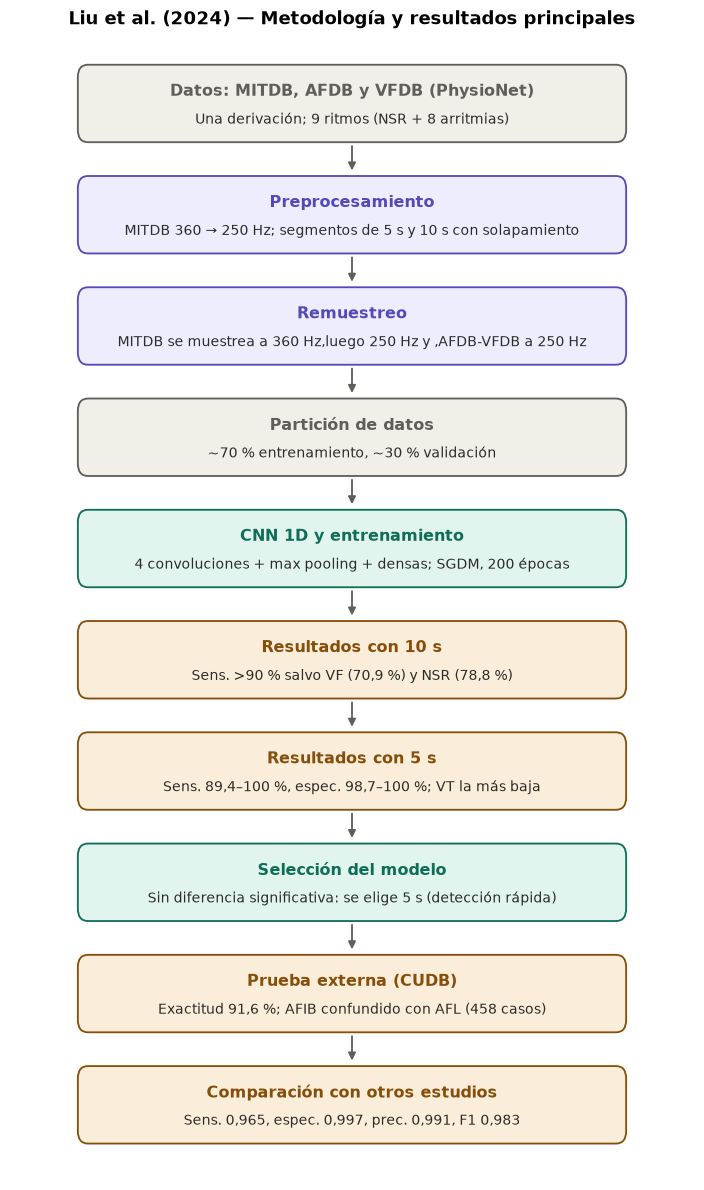

In [13]:
# Agrega una nueva categoría de color al diccionario: ámbar (relleno, borde) para las etapas de resultados
COLORES["resultado"] = ("#FAEEDA", "#854F0B")   # ámbar para resultados

# Lista de etapas del diagrama; cada tupla es (título de la caja, texto de detalle, categoría de color)
etapas = [
    ("Datos: MITDB, AFDB y VFDB (PhysioNet)", "Una derivación; 9 ritmos (NSR + 8 arritmias)",                  "datos"),
    ("Preprocesamiento",                      "MITDB 360 → 250 Hz; segmentos de 5 s y 10 s con solapamiento",  "proc"),
    ("Remuestreo",                            "MITDB se muestrea a 360 Hz,luego 250 Hz y ,AFDB-VFDB a 250 Hz", "proc"),
    ("Partición de datos",                    "~70 % entrenamiento, ~30 % validación",                         "datos"),
    ("CNN 1D y entrenamiento",                "4 convoluciones + max pooling + densas; SGDM, 200 épocas",      "modelo"),
    ("Resultados con 10 s",                   "Sens. >90 % salvo VF (70,9 %) y NSR (78,8 %)",                  "resultado"),
    ("Resultados con 5 s",                    "Sens. 89,4–100 %, espec. 98,7–100 %; VT la más baja",           "resultado"),
    ("Selección del modelo",                  "Sin diferencia significativa: se elige 5 s (detección rápida)", "modelo"),
    ("Prueba externa (CUDB)",                 "Exactitud 91,6 %; AFIB confundido con AFL (458 casos)",         "resultado"),
    ("Comparación con otros estudios",        "Sens. 0,965, espec. 0,997, prec. 0,991, F1 0,983",              "resultado"),
]

# Llama a la función que dibuja el flujo con la lista de etapas y el título que va arriba del diagrama
dibujar_flujo(etapas, "Liu et al. (2024) — Metodología y resultados principales")

**Metodología utilizada en el artículo**

**Objetivo de la investigación:** Los autores querían saber si una red neuronal convolucional 1D puede clasificar nueve ritmos cardíacos (el ritmo sinusal normal y ocho arritmias) usando solo una derivación del ECG y sin pasar por la detección del complejo QRS, que es lo que hacía la mayoría de trabajos anteriores. También querían comparar ventanas de 5 s y 10 s para ver si una señal más corta da resultados parecidos. Si eso se cumple, se podría detectar una arritmia más rápido, algo útil en urgencias y en dispositivos portátiles de uso diario.

**Metodología**

**-Datos:** Se tomaron los nueve ritmos de tres bases de PhysioNet (MITDB, AFDB y VFDB) usando la librería WFDB. Como MITDB está muestreada a 360 Hz y las otras dos a 250 Hz, la bajaron a 250 Hz para que todas quedaran iguales.

**-Segmentación:** En lugar de cortar la señal a partir de los latidos, la dividieron en segmentos de 5 s (1250 muestras) o de 10 s (2500 muestras). Para los ritmos con pocos datos usaron un método de solapamiento: una ventana que se desplaza y genera segmentos que se traslapan, y dos segmentos consecutivos forman una muestra nueva. Así aumentaron el número de muestras sin tener que conseguir más registros.

**-Partición:** Separaron los datos en entrenamiento y validación, aproximadamente 70 % y 30 %. Con 5 s quedaron 5734 muestras de entrenamiento y 2568 de validación, y con 10 s quedaron 5934 y 2525.

**-Construcción de Red Neuronal Convolucional:** La arquitectura se basó en un trabajo previo de Acharya et al. Tiene cuatro capas convolucionales con filtros de tamaño 27, 24, 15 y 10 (64 filtros cada una), y después de cada una hay un max pooling de tamaño 2. Luego vienen tres capas completamente conectadas de 1250, 10 y 8 neuronas, y una softmax para obtener la clase.

**-Entrenamiento:** Usaron descenso de gradiente estocástico con momento, minibatch de 20 y 200 épocas, con GPU para acelerar el proceso.

**-Evaluación interna:** Calcularon exactitud, sensibilidad y especificidad por clase y revisaron las matrices de confusión. Los modelos de 5 s y 10 s rindieron de forma similar. El de 10 s falló más con VF y NSR (sensibilidad de 70,9 % y 78,8 %), y el de 5 s tuvo su peor resultado en VT (89,4 %). Gran parte de los errores fueron confusiones entre VT y VF, que en la práctica clínica se manejan igual con desfibrilación.

**-Validación externa:** Como el de 5 s detecta más rápido, escogieron ese modelo y lo probaron con la base CUDB, usando los registros completos y sin solapamiento, para ver cómo se comporta con datos que nunca vio. La exactitud promedio fue de 91,6 %. El error más frecuente fue confundir AFIB con AFL (458 casos), que los autores relacionan con el desbalance de clases de esa base.

**-Cierre:** Compararon sus métricas con las de otros estudios y reconocieron limitaciones: no incluyeron otras arritmias como PSVT o PVC, el ECG es sensible al ruido y las bases públicas ya vienen depuradas, así que falta validar con datos clínicos reales.

**Resultados principales obtenidos por los investigadores:** Los dos modelos tuvieron un desempeño alto y comparable. Con ventanas de 10 s, la exactitud por clase estuvo entre 95,3 % y 99,8 %, y la sensibilidad superó el 90 % en siete de los nueve ritmos; las excepciones fueron VF (70,9 %) y NSR (78,8 %), cuyos errores se concentraron en la confusión de VF con VT y de NSR con VFL. Con ventanas de 5 s, la sensibilidad fue de 89,4 % a 100 % y la especificidad de 98,7 % a 100 %, con VT como la clase más débil (89,4 %), confundida sobre todo con VF. Como no hubo diferencias estadísticamente significativas entre ambos, los autores eligieron el modelo de 5 s por permitir una detección más rápida, y al probarlo con la base externa CUDB obtuvieron una exactitud promedio de 91,6 %, con AFIB clasificado erróneamente como AFL en 458 casos, error que atribuyen al desbalance de clases de esa base. En la comparación con trabajos previos, el modelo alcanzó una sensibilidad de 0,965, una especificidad de 0,997, una precisión de 0,991 y un F1 de 0,983 (Tabla 4), sin necesidad de detectar el QRS y usando una sola derivación.

## **1.2. Optimal Multi-Stage Arrhythmia Classification Approach**

Enlace de acceso artículo 2: https://www.nature.com/articles/s41598-020-59821-7

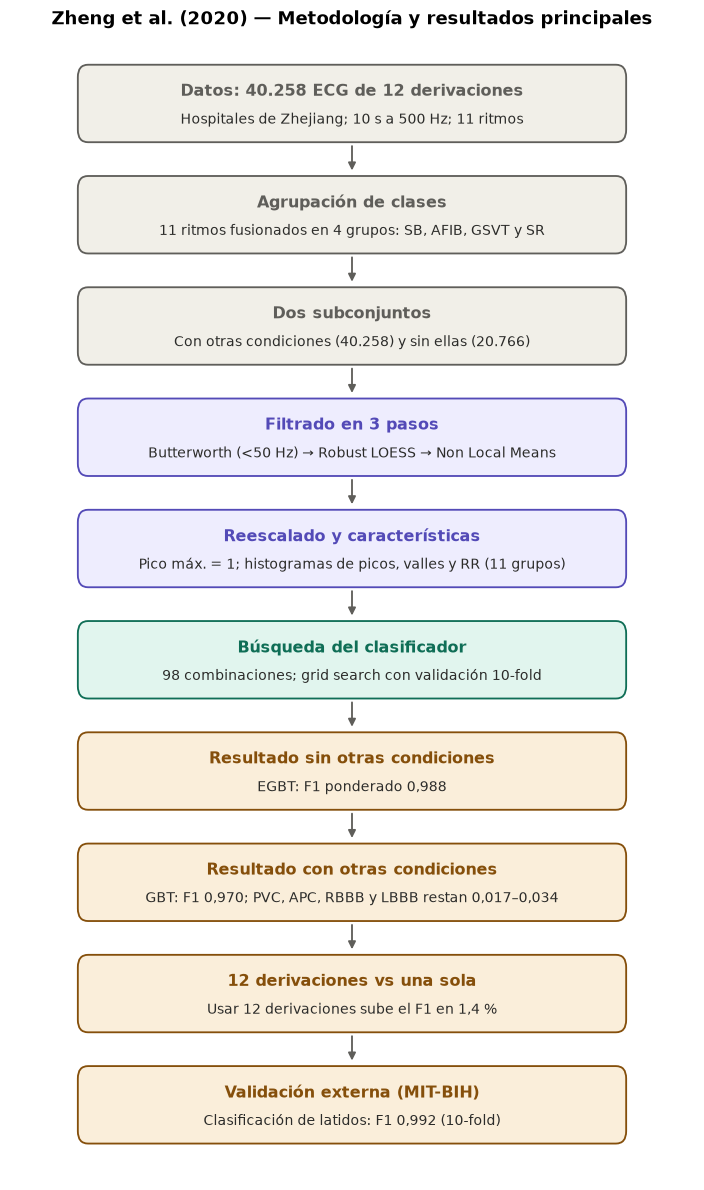

In [14]:
# Agrega una nueva categoría de color al diccionario: ámbar (relleno, borde) para las etapas de resultados
COLORES["resultado"] = ("#FAEEDA", "#854F0B")   # ámbar para resultados

# Lista de etapas del diagrama; cada tupla es (título de la caja, texto de detalle, categoría de color)
etapas = [
    ("Datos: 40.258 ECG de 12 derivaciones",  "Hospitales de Zhejiang; 10 s a 500 Hz; 11 ritmos",               "datos"),
    ("Agrupación de clases",                  "11 ritmos fusionados en 4 grupos: SB, AFIB, GSVT y SR",          "datos"),
    ("Dos subconjuntos",                      "Con otras condiciones (40.258) y sin ellas (20.766)",            "datos"),
    ("Filtrado en 3 pasos",                   "Butterworth (<50 Hz) → Robust LOESS → Non Local Means",          "proc"),
    ("Reescalado y características",          "Pico máx. = 1; histogramas de picos, valles y RR (11 grupos)",   "proc"),
    ("Búsqueda del clasificador",             "98 combinaciones; grid search con validación 10-fold",           "modelo"),
    ("Resultado sin otras condiciones",       "EGBT: F1 ponderado 0,988",                                       "resultado"),
    ("Resultado con otras condiciones",       "GBT: F1 0,970; PVC, APC, RBBB y LBBB restan 0,017–0,034",        "resultado"),
    ("12 derivaciones vs una sola",           "Usar 12 derivaciones sube el F1 en 1,4 %",                       "resultado"),
    ("Validación externa (MIT-BIH)",          "Clasificación de latidos: F1 0,992 (10-fold)",                   "resultado"),
]

# Llama a la función que dibuja el flujo con la lista de etapas y el título que va arriba del diagrama
dibujar_flujo(etapas, "Zheng et al. (2020) — Metodología y resultados principales")

**Objetivo de la investigación:** Los autores querían encontrar el esquema multietapa óptimo para clasificar arritmias a partir de ECG de 12 derivaciones, con una exactitud al nivel de cardiólogos profesionales. En lugar de proponer un solo algoritmo, optimizaron toda la cadena (reducción de ruido, extracción de características y clasificador) comparando cientos de combinaciones sobre una base de datos propia y grande. También buscaban medir dos cosas que no se habían estudiado: cuánto mejora la clasificación al usar 12 derivaciones en vez de una sola, y cuánto la empeoran otras condiciones cardíacas presentes en el paciente (PVC, APC, RBBB, LBBB). Además, querían que el método fuera aplicable a datos de dispositivos portátiles y a otras fuentes de ECG.

**Metodología**

1. **Base de datos:** Usaron 40.258 ECG de 12 derivaciones (22.599 hombres y 17.659 mujeres) de dos hospitales de Zhejiang, China, entre 2013 y 2018. Cada registro dura 10 s, fue tomado a 500 Hz y etiquetado por médicos supervisados por cardiólogos, con 11 tipos de ritmo y 67 hallazgos cardíacos adicionales.

2. **Agrupación de clases:** Como algunos ritmos tenían muy pocos casos, los 11 ritmos se fusionaron en 4 grupos:

SB: bradicardia sinusal.
AFIB: fibrilación y flutter auricular.
GSVT: taquicardias supraventriculares (SVT, AT, AVNRT, AVRT) y marcapasos auricular errante.
SR: ritmo sinusal e irregularidad sinusal.

3. **Dos conjuntos de datos:** Se trabajó con la base completa (pacientes con otras condiciones cardíacas) y con un subconjunto de 20.766 ECG sin ellas, para evaluar el efecto de esas condiciones.

4. **Reducción de ruido en tres pasos:**

-Filtro pasa bajas Butterworth, para eliminar ruido de alta frecuencia (por encima de 50 Hz).

-Robust LOESS (Regresión Local robusta), para quitar la deriva de la línea base.

-Non Local Means (NLM), para eliminar el ruido restante. Usa un kernel gaussiano, ventana de 10 y un parámetro de suavizado de 1,5 veces la desviación estándar del ruido, estimada con MAD.

5. **Reescalado:** Cada señal se normalizó para que su pico máximo fuera 1. Luego repitieron el análisis sin reescalar para medir el efecto, de modo que quedaron 44 conjuntos de datos.

6. **Extracción de características:** Detectaron picos y valles (complejo QRS, picos no QRS y valles) y midieron su altura, ancho y prominencia, además de los intervalos RR. Como cada paciente tiene un número distinto de picos, construyeron una tabla de distribución empírica de frecuencias en 100 intervalos para cada atributo y para las razones entre diferencias de altura, ancho y prominencia sobre la diferencia de tiempo. Así obtuvieron hasta 39.830 características.

7. **Grupos de características:** Definieron 11 combinaciones (Tabla 8), desde 11 variables básicas entregadas por el equipo de ECG (grupo 1) hasta todas las derivaciones juntas (grupo 11). Esto permitió comparar 12 derivaciones contra una sola.

8. **Búsqueda de clasificador:** Probaron 19 algoritmos base (DT, KNN, Naive Bayes, regresión logística, redes, SVC, Random Forest, ERT, GBT, EGBT, entre otros), combinados con estrategias de ensamble y de descomposición multiclase (bagging, AdaBoost, OneVsRest, OneVsOne y códigos de corrección de errores). En total compararon 98 combinaciones.

9. **Ajuste de hiperparámetros:** Hicieron una búsqueda exhaustiva en rejilla (grid search) con validación cruzada de 10 pliegues, eligiendo los valores con mayor F1 ponderado.

10. **Evaluación:** Validación cruzada de 10 pliegues (80 % entrenamiento, 20 % prueba), con F1 ponderado, precisión, sensibilidad y matrices de confusión.

11. **Validación externa:** Aplicaron el método a la base MIT-BIH para clasificar latidos individuales (normal, marcapasos, bloqueo de rama izquierda, bloqueo de rama derecha y contracción ventricular prematura), usando dos intervalos RR cercanos a cada latido para extraer las características y validación cruzada con 90 % de entrenamiento y 10 % de prueba.

**Resultados principales:** El mejor esquema combinó el filtrado en tres pasos, las características basadas en distribuciones de frecuencia y clasificadores de boosting de árboles (EGBT y GBT, que dominaron la mayoría de los grupos de características). En pacientes sin otras condiciones cardíacas, el modelo EGBT alcanzó un F1 ponderado de 0,988 (AFIB 0,964, GSVT 0,979, SB 0,996 y SR 0,989). En pacientes con otras condiciones, el GBT alcanzó 0,97 (AFIB 0,941, GSVT 0,949, SB 0,993 y SR 0,977), y esas condiciones (PVC, RBBB, LBBB y APC) redujeron el F1 entre 0,017 y 0,034 con el mismo grupo de características. Usar 12 derivaciones en lugar de una sola subió el F1 en 1,4 %, y las características propuestas por los autores superaron a las que entrega el equipo de ECG (diferencia de 0,021 entre los grupos 1 y 2). Reescalar las señales tuvo un efecto positivo muy pequeño (alrededor de 0,001 de F1). En la validación externa con MIT-BIH obtuvieron un F1 de 0,992 en promedio, el más alto frente a los estudios con los que se compararon, y con una ventaja práctica: las características son interpretables, a diferencia de las de las redes profundas.

## **1.2. Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias**

Enlace de acceso artículo 3: https://www.nature.com/articles/s41746-023-00966-w

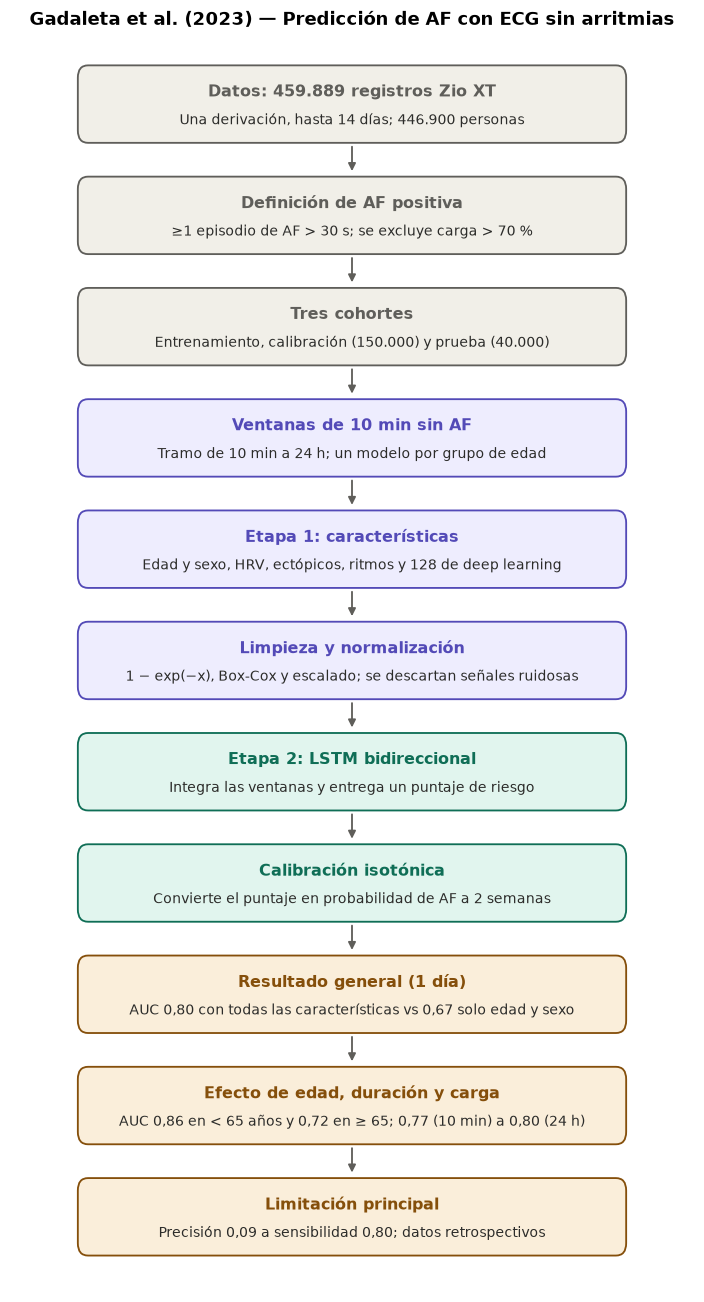

In [15]:
# Categoría de color nueva para resultados (si ya la definiste antes, esta línea no cambia nada)
COLORES["resultado"] = ("#FAEEDA", "#854F0B")   # ámbar para resultados

# Lista de etapas del diagrama; cada tupla es (título de la caja, texto de detalle, categoría de color)
etapas = [
    ("Datos: 459.889 registros Zio XT",       "Una derivación, hasta 14 días; 446.900 personas",                "datos"),
    ("Definición de AF positiva",             "≥1 episodio de AF > 30 s; se excluye carga > 70 %",              "datos"),
    ("Tres cohortes",                         "Entrenamiento, calibración (150.000) y prueba (40.000)",         "datos"),
    ("Ventanas de 10 min sin AF",             "Tramo de 10 min a 24 h; un modelo por grupo de edad",            "proc"),
    ("Etapa 1: características",              "Edad y sexo, HRV, ectópicos, ritmos y 128 de deep learning",     "proc"),
    ("Limpieza y normalización",              "1 − exp(−x), Box-Cox y escalado; se descartan señales ruidosas", "proc"),
    ("Etapa 2: LSTM bidireccional",           "Integra las ventanas y entrega un puntaje de riesgo",            "modelo"),
    ("Calibración isotónica",                 "Convierte el puntaje en probabilidad de AF a 2 semanas",         "modelo"),
    ("Resultado general (1 día)",             "AUC 0,80 con todas las características vs 0,67 solo edad y sexo", "resultado"),
    ("Efecto de edad, duración y carga",      "AUC 0,86 en < 65 años y 0,72 en ≥ 65; 0,77 (10 min) a 0,80 (24 h)", "resultado"),
    ("Limitación principal",                  "Precisión 0,09 a sensibilidad 0,80; datos retrospectivos",       "resultado"),
]

# Llama a la función que dibuja el flujo con la lista de etapas y el título que va arriba del diagrama
dibujar_flujo(etapas, "Gadaleta et al. (2023) — Predicción de AF con ECG sin arritmias")

**Objetivo de la investigación:** Los autores querían construir un modelo que estime el riesgo de que una persona presente fibrilación auricular (AF) o flutter en las siguientes dos semanas, usando únicamente tramos de ECG de una derivación en los que no aparece ninguna AF. La idea es identificar a quienes tienen fibrilación paroxística que un monitoreo corto no logró captar, para recomendarles un monitoreo más largo o repetido. También querían medir cuánto aporta cada tipo de información (edad y sexo, variabilidad de la frecuencia cardíaca, latidos ectópicos y características aprendidas por deep learning) y cómo cambia la predicción según la edad, la duración del registro y la carga de AF.

**Metodología**

1. **Datos:** Se usaron 459.889 registros de 446.900 personas con el parche Zio XT de iRhythm (una derivación, hasta 14 días), tomados entre enero de 2019 y mayo de 2022. Se excluyeron las personas con AF persistente (carga mayor al 70 %). Se consideró positiva a una persona con al menos un episodio de AF de más de 30 s verificado por un técnico certificado.

2. **División de cohortes:** Hubo tres cohortes separadas: entrenamiento (269.889 registros, enriquecidos con casos de AF), calibración (150.000 registros con prevalencia natural) y prueba (40.000 registros). Se entrenó un modelo por grupo de edad (18-54, 55-64, 65-74, 75-84 y 85-99).

3. **Entrada del modelo:** Un tramo de ECG sin AF, de entre 10 min y 24 h, dividido en ventanas de 10 min.

4. **Primera etapa (por ventana de 10 min):** Se extraen cuatro grupos de características: Demografía (edad y sexo).Métricas de variabilidad de la frecuencia cardíaca (HRV), calculadas con los picos R sin contar los ectópicos. Latidos ectópicos (PAC y PVC) y otros ritmos anormales, tomados de las anotaciones del reporte clínico.
128 características de aprendizaje de representación, generadas por una red profunda (módulo A) a partir de la morfología del ECG. Sus pesos se congelan tras entrenarla.

5. **Limpieza y normalización:** Transformación 1 − exp(−x) para las cargas de ritmo, Box-Cox para el resto, eliminación del offset y escalado. Se descartaron señales con frecuencia media menor a 20 lpm, más de 2 min de artefactos en la ventana o muy pocos picos R.

6. **Segunda etapa:** Las características de las ventanas consecutivas entran a un módulo B: una LSTM bidireccional de dos capas, pooling y dos capas completamente conectadas, que integran la información de todo el tramo y entregan un puntaje de riesgo.

7. **Calibración:** Con regresión isotónica sobre la cohorte de calibración, el puntaje se convierte en la probabilidad real de AF en la ventana de observación y queda en la misma escala para todas las edades.

8. **Configuraciones comparadas:** Se entrenó el modelo con distintas entradas: solo edad y sexo (AG), AG + HRV, AG + ectópicos, AG + HRV + ectópicos + ritmo, solo deep learning (DL Only) y todas las características (All Features).

9. **Evaluación:** Se usó AUC y precisión promedio, con intervalos de confianza al 95 % por bootstrap de 10.000 iteraciones y pruebas pareadas para comparar modelos. Se analizó por edad (menores y mayores de 65), por duración del registro (10 min, 1 h y 24 h) y por carga de AF (baja menor al 1 %, media de 1 a 10 % y alta mayor al 10 %).

**Resultados principales:** Con un registro de 1 día sin AF y una prevalencia de 4,3 %, el modelo con todas las características alcanzó un AUC de 0,80 (IC 0,79-0,81), frente a 0,67 del modelo con solo edad y sexo y 0,74 al agregar HRV, una mejora de 0,12 sobre el modelo demográfico. El modelo con solo características de deep learning rindió casi igual que el completo (diferencia mínima de AUC), lo que indica que la red extrae bien la información relevante de la morfología. Por edad, el AUC fue 0,86 en menores de 65 años y 0,72 en mayores, donde el modelo demográfico casi no discrimina (0,53). Un registro más largo mejoró la predicción: el AUC pasó de 0,77 con 10 min a 0,80 con 24 h, mientras que el modelo demográfico no cambió. El AUC también subió con la carga de AF (0,76, 0,80 y 0,90 para carga baja, media y alta), y la mayor ventaja del deep learning apareció en la carga media, con 0,80 frente a 0,69 del modelo demográfico. A una sensibilidad fija de 0,80, la especificidad global fue de 0,65, con precisión de 0,09 y F1 de 0,17.

## 2.Análisis estadístico generalizado y preguntas informativas del Dataset

2. Cargar el archivo Diagnostics.xlsx y realizar un análisis estadístico general de los datos. Desde la información en la base de datos resolver las siguientes preguntas 

In [16]:

df = pd.read_excel("Diagnostics.xlsx")
# Observación preliminar de las variables y estructura del dataset
df.describe()



,PatientAge,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
count,10646.000000,10646.000000,10646.00000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000
mean,59.186831,84.136107,92.57787,90.989292,384.150855,434.154048,39.620609,44.637704,13.839470,219.260567,264.755213,411.335995
std,18.030019,34.455349,60.09394,17.479540,59.226289,39.354182,41.212648,57.478092,5.676339,6.410413,8.362120,29.777404
min,4.000000,34.000000,0.00000,18.000000,114.000000,219.000000,-89.000000,-89.000000,5.000000,159.000000,249.000000,281.000000
25%,49.000000,57.000000,57.00000,80.000000,344.000000,408.000000,14.000000,19.000000,9.000000,216.000000,259.000000,392.000000
50%,62.000000,73.000000,72.00000,88.000000,390.000000,430.000000,46.000000,42.000000,12.000000,219.000000,264.000000,414.000000
75%,72.000000,104.000000,106.00000,98.000000,426.000000,456.000000,68.000000,62.000000,17.000000,224.000000,268.000000,432.000000
max,98.000000,263.000000,535.00000,256.000000,736.000000,760.000000,270.000000,270.000000,40.000000,240.000000,331.000000,582.000000


In [17]:
df.groupby(by=["Rhythm"]).describe()

PatientAge                                                       \
            count       mean        std   min    25%   50%   75%   max   
Rhythm                                                                   
AF          445.0  71.065169  13.497673  21.0  63.00  72.0  81.0  97.0   
AFIB       1780.0  73.359551  11.137343  30.0  67.00  75.0  82.0  98.0   
AT          121.0  65.719008  19.300787   8.0  60.00  71.0  77.0  94.0   
AVNRT        16.0  57.875000  17.335417  27.0  51.00  59.0  66.0  84.0   
AVRT          8.0  57.500000  16.835337  25.0  47.75  62.5  67.0  77.0   
SA          399.0  34.746867  23.029446   4.0  14.50  29.0  52.5  93.0   
SAAWR         7.0  51.142857  31.829905  15.0  22.50  49.0  81.0  87.0   
SB         3889.0  58.339676  13.952579  10.0  50.00  60.0  68.0  98.0   
SR         1826.0  54.352136  16.331977   4.0  44.00  55.0  66.0  95.0   
ST         1568.0  54.565051  21.060029   4.0  40.00  57.0  70.0  96.0   
SVT         587.0  55.623509  18.527343   4.0  42.00  56.0  69.0  96.0   

       VentricularRate              ... QOffset        TOffset              \
                 count        mean  ...     75%    max   count        mean   
Rhythm                              ...                                      
AF               445.0  114.577528  ...  272.00  314.0   445.0  392.907865   
AFIB            1780.0   95.489326  ...  269.00  311.0  1780.0  402.439888   
AT               121.0  116.438017  ...  267.00  294.0   121.0  387.388430   
AVNRT             16.0  172.250000  ...  271.00  316.0    16.0  359.062500   
AVRT               8.0  171.000000  ...  266.75  274.0     8.0  358.125000   
SA               399.0   72.922306  ...  266.50  299.0   399.0  411.834586   
SAAWR              7.0   64.428571  ...  266.00  274.0     7.0  423.428571   
SB              3889.0   55.022885  ...  269.00  314.0  3889.0  435.605554   
SR              1826.0   75.748083  ...  267.00  311.0  1826.0  413.105148   
ST              1568.0  112.157526  ...  266.00  303.0  1568.0  386.538265   
SVT              587.0  168.367973  ...  271.00  331.0   587.0  358.831346   

                                                       
              std    min    25%    50%     75%    max  
Rhythm                                                 
AF      34.783087  302.0  369.0  389.0  412.00  537.0  
AFIB    26.553652  307.0  385.0  403.0  420.00  562.0  
AT      25.048743  323.0  372.0  387.0  403.00  490.0  
AVNRT   10.009787  334.0  355.5  359.5  363.25  381.0  
AVRT    26.351674  318.0  338.0  364.0  378.25  390.0  
SA      15.496724  376.0  400.5  411.0  421.00  466.0  
SAAWR   15.576233  406.0  414.0  421.0  428.00  453.0  
SB      17.177428  385.0  424.0  434.0  445.00  582.0  
SR      14.925198  370.0  403.0  413.0  423.00  494.0  
ST      15.636704  328.0  377.0  387.0  395.00  559.0  
SVT     19.553825  281.0  347.0  359.0  371.00  475.0  

[11 rows x 96 columns]

¿Qué tipo de arritmias son más prevalentes? 

In [18]:
plt.figure(figsize=(10, 10))
sns.histplot(df['Rhythm'], bins=10, kde=False, color='black')

plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

NameError: name 'sns' is not defined

<Figure size 1100x1100 with 0 Axes>

¿Hay arritmias que son más prevalentes para un género específico?

In [ ]:
df['Gender'].value_counts()

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64

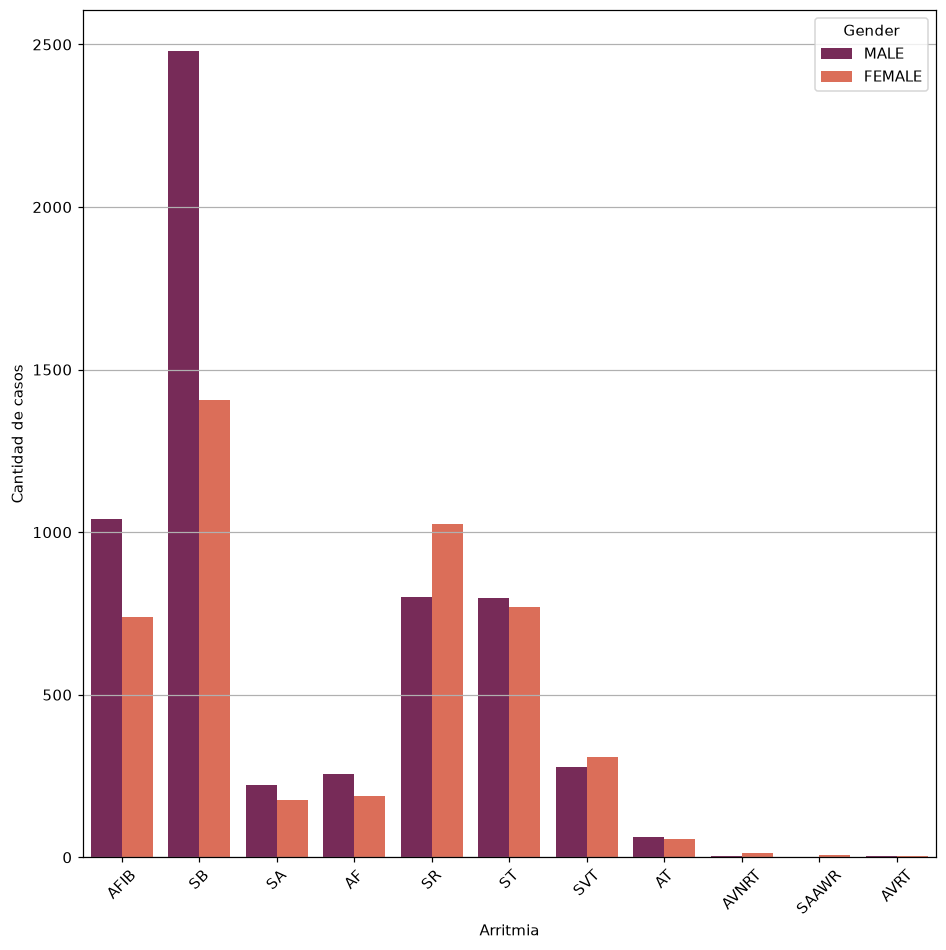

In [ ]:
plt.figure(figsize=(10, 10))
sns.countplot(data=df, x='Rhythm', hue='Gender', palette='rocket')
plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25092\2861780615.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Rhythm', y='PatientAge', palette='rocket')


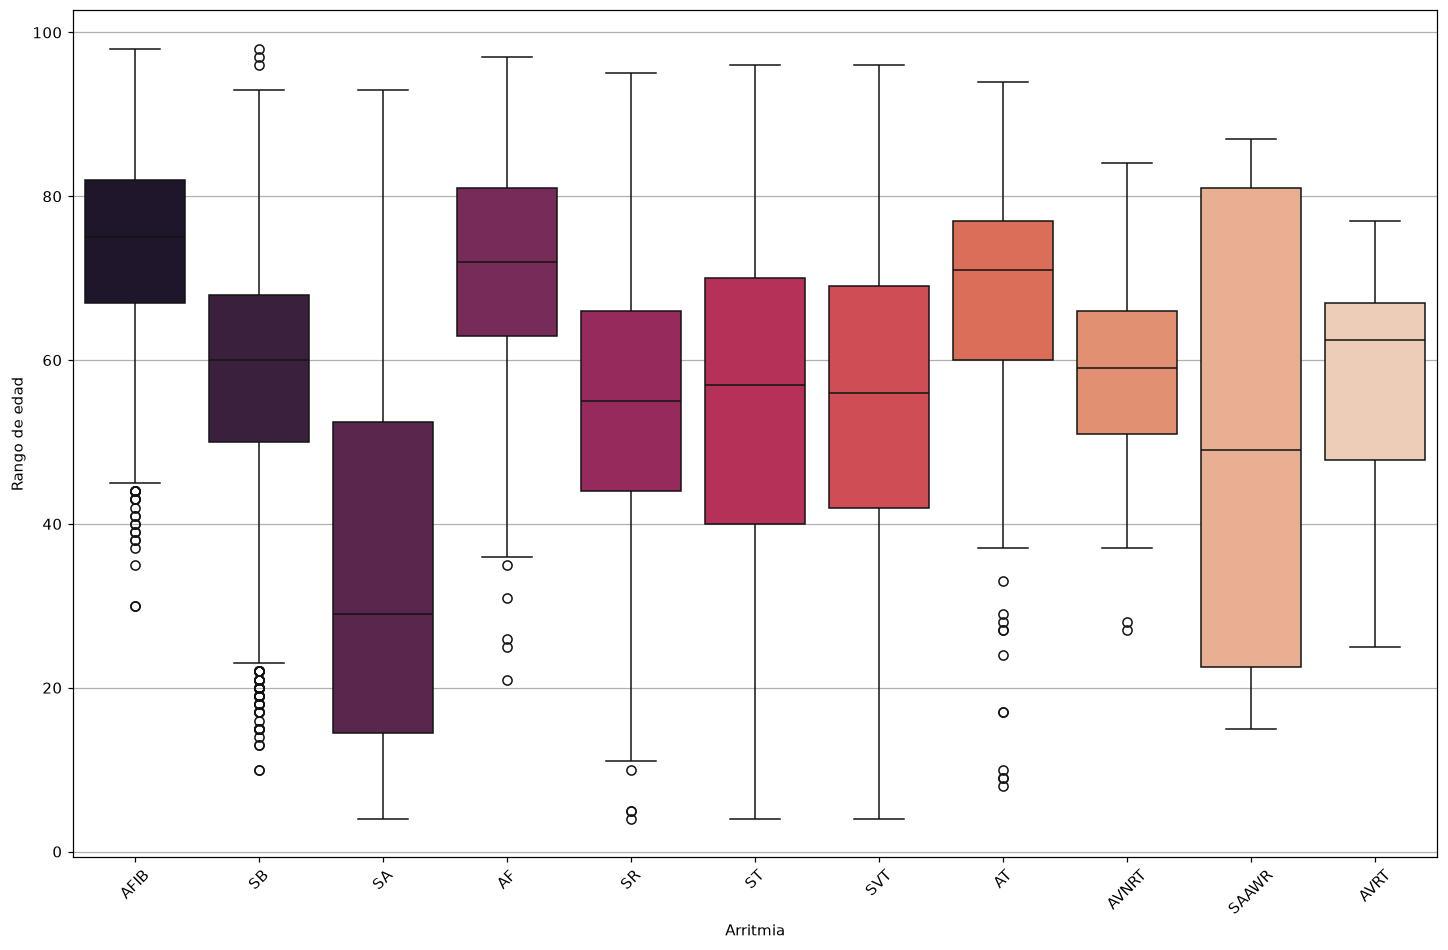

In [ ]:
plt.figure(figsize=(16, 10))
sns.boxplot(data=df, x='Rhythm', y='PatientAge', palette='rocket')
plt.ylabel('Rango de edad')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

¿Hay arritmias que son más prevalentes para una edad?

<Axes: xlabel='PatientAge', ylabel='Count'>

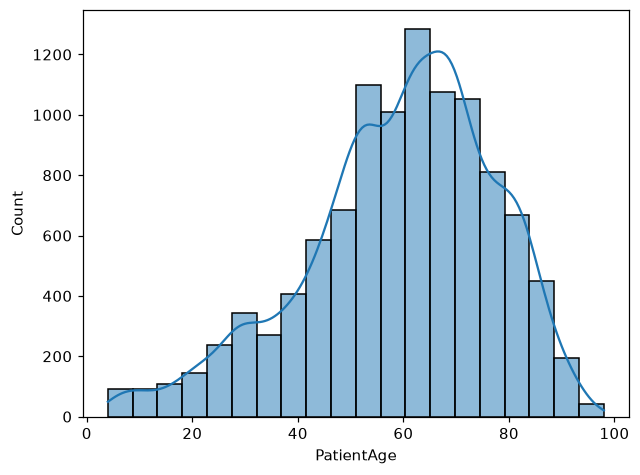

In [ ]:
df['PatientAge'].describe()
sns.histplot(df['PatientAge'], bins=20, kde=True)

<Axes: xlabel='PatientAge', ylabel='Count'>

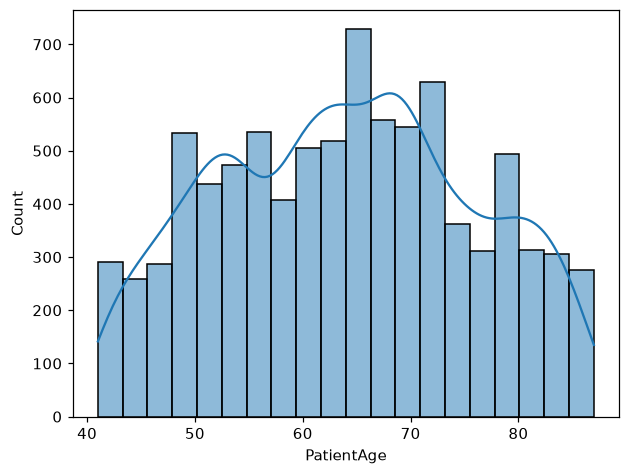

In [ ]:
df_filtrado = df[(df['PatientAge'] >= 41) & (df['PatientAge'] <= 87)]
df_filtrado.describe()
sns.histplot(df_filtrado['PatientAge'], bins=20, kde=True)

Los algoritmos de aprendizaje se basan en usar la mayor cantidad de datos posibles que sean comparables, ¿Qué rango de edades y arritmias de la base de datos entregada considera que debe usar para entrenar algoritmos de aprendizaje? 

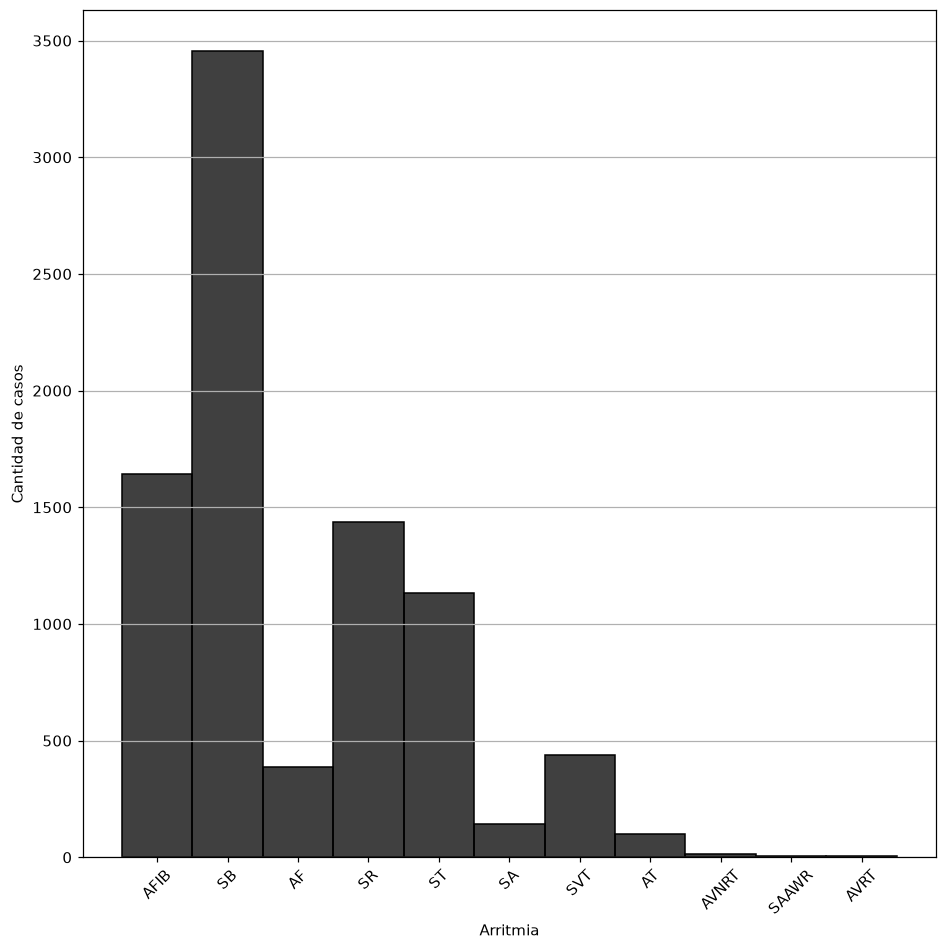

In [ ]:
plt.figure(figsize=(10, 10))
sns.histplot(df_filtrado['Rhythm'], bins=10, kde=False, color='black')
plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25092\4103379746.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtrado, x='Rhythm', y='PatientAge', palette='rocket')


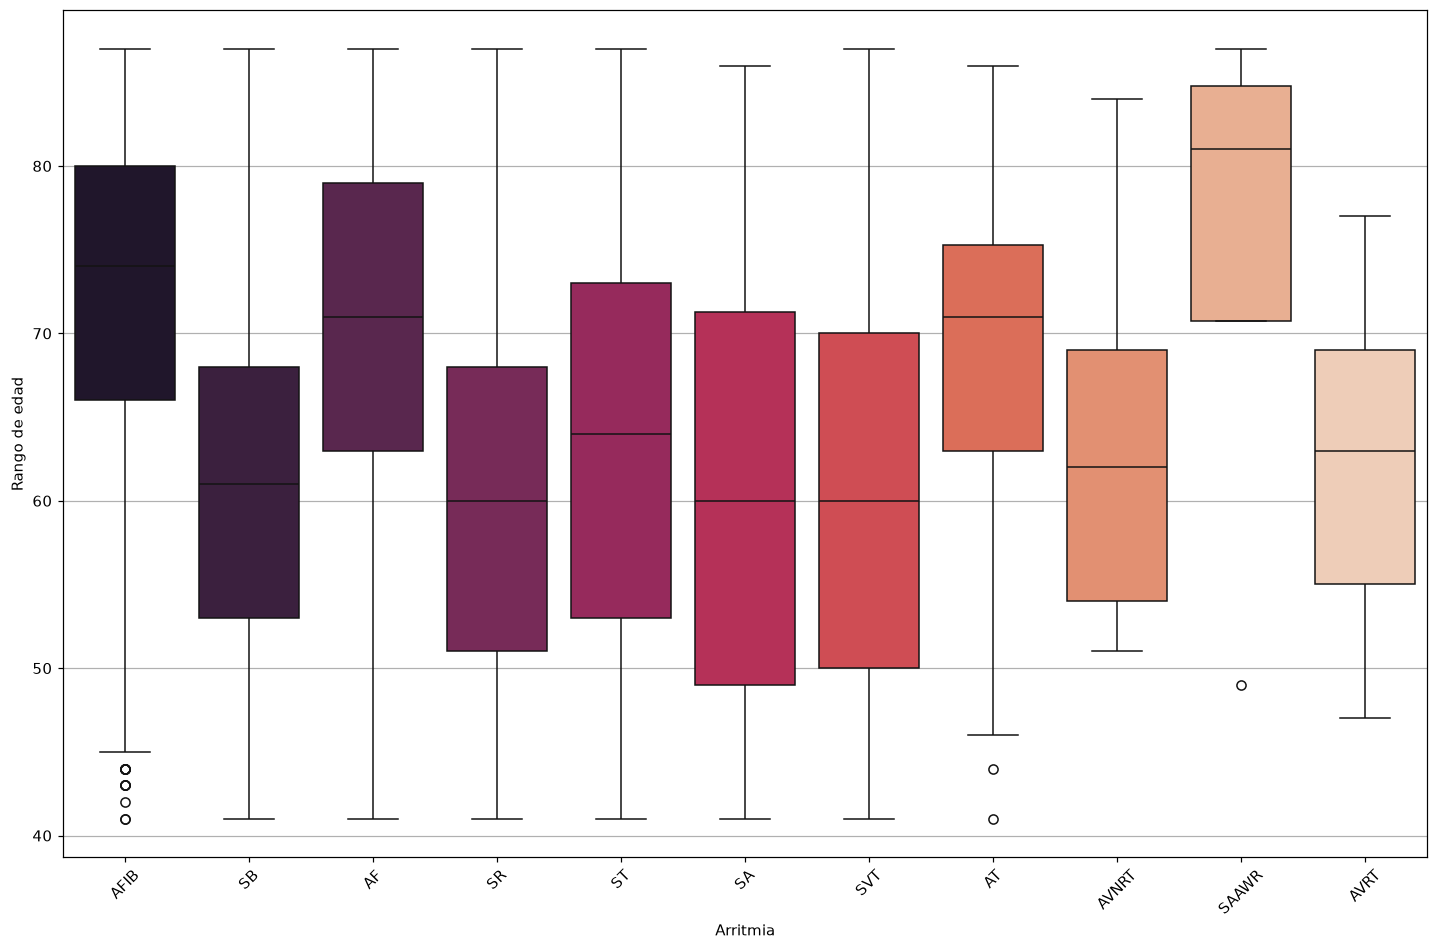

In [ ]:
plt.figure(figsize=(16, 10))
sns.boxplot(data=df_filtrado, x='Rhythm', y='PatientAge', palette='rocket')
plt.ylabel('Rango de edad')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

¿Hay coincidencia entre lo encontrado en literatura y lo encontrado en la base de datos? 

 ¿Qué otros análisis propone desde la base de datos?

Con base en el análisis descriptivo del punto anterior, seleccionar un subconjunto de datos para trabajar en los siguientes análisis. 
3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%). 

Consultar que significado y utilidad del biespectro (5%) https://arxiv.org/pdf/1809.08451 

## 3. Fórmulas del artículo y significado-utilidad del biespectro

3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%). 
Consultar que significado y utilidad del biespectro (5%)

## 4.Frecuencia de máxima potencia de las señales

4. Para cada señal extraer la frecuencia que contiene la máxima potencia 
(15%). 

## 5.Suma de frecuencias significativas de cada señal (sFSB)

5. Para cada señal, sumar el número de frecuencias que son significativas para bicoherencia (aquellas con un valor superior a $\sqrt{\dfrac{9.2}{2 \cdot N}}$ (10 %)).

## 6. Rutina aplicada al Dataframe para el registro, tipo de patología, la fMP y frecuencias significativas

6. Crear una rutina que aplique sobre todos los archivos de la base de datos las rutinas 3 al 5 y almacene los resultados en un dataframe donde se pueda registrar el registro, tipo de patología y la frecuencia de máxima potencia (fMP) y suma de frecuencias significativas en bicoherencia (sFSB) (10 %)

<div align="center">

| Registro | Estado | fMP | sFSB |
|:--------:|:------:|:---:|:----:|
|          |        |     |      |
|          |        |     |      |

</div>

## 7. Estadística descriptiva para cada arritmia

7. Para las señales de análisis del punto 2 aplicar las rutinas del punto 3 al 
5  y  hacer  un  informe  que  permita  evidenciar  las  diferencias  entre  las 
señales las diferentes arritmias utilizando las herramientas de estadística 
descriptiva (5%). 

## 8. Diferencia estadística a través de pruebas estadísticas

8. Indicar  si  hay  o  no  diferencias  estadísticas  entre  las  características 
espectrales del punto 4 y 5 para las poblaciones de estudio (5%)

## 9. Análisis de resultados y conclusiones

9. Hacer un informe con todos los puntos anteriores. El informe debe 
incluir análisis de resultados y conclusiones (15%). Trabajo sin sustentar 
no se califica

## 10. Bibliografía

[1] L.-R. Liu et al., “An arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection,” Heliyon, vol. 10, Art. no. e27200, Feb. 2024, doi: 10.1016/j.heliyon.2024.e27200.

[2] J. Zheng et al., “Optimal multi-stage arrhythmia classification approach,” Sci. Rep., vol. 10, Art. no. 2898, Feb. 2020, doi: 10.1038/s41598-020-59821-7.

[3] M. Gadaleta et al., “Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias,” npj Digit. Med., vol. 6, Art. no. 229, Dec. 2023, doi: 10.1038/s41746-023-00966-w.